# Bike-share data: solution plots (instructor copy)

One plot (or two) per planted finding in `bike_share.csv`. Run top to bottom; each section is self-contained after the setup cell.

| Tier | Finding |
|---|---|
| Easy | 1 Commuter double peak, 2 Weekday vs weekend, 3 Warmer means more rentals |
| Medium | 4 Three hidden station types, 5 Rain hurts weekends more |
| Hard | 6 Temperature effect turns over, 7 Capacity ceiling |
| Red herring | Humidity |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

df = pd.read_csv("bike_share.csv")
df["weekend"] = df.weekday >= 5
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(df.shape)
df.head()

(8064, 12)


,station,x,y,day,hour,weekday,temp,humidity,wind,rain,rentals,weekend
0,1,-1.29,-0.43,1,0,0,16.1,74,2.4,0,1,False
1,1,-1.29,-0.43,1,1,0,15.5,62,3.2,0,0,False
2,1,-1.29,-0.43,1,2,0,16.0,74,4.1,0,0,False
3,1,-1.29,-0.43,1,3,0,14.6,70,2.3,0,1,False
4,1,-1.29,-0.43,1,4,0,14.6,73,4.5,0,2,False


In [2]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
station,8064.0,6.50,3.45,1.00,3.75,6.50,9.25,12.00
x,8064.0,0.71,2.17,-4.03,-0.54,0.57,2.40,3.68
y,8064.0,0.01,2.00,-3.14,-1.58,0.10,1.33,3.56
day,8064.0,14.50,8.08,1.00,7.75,14.50,21.25,28.00
hour,8064.0,11.50,6.92,0.00,5.75,11.50,17.25,23.00
weekday,8064.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00
temp,8064.0,18.71,4.51,7.80,15.30,18.60,21.90,28.90
humidity,8064.0,69.12,10.56,46.00,62.00,67.00,75.00,100.00
wind,8064.0,3.07,1.47,0.00,2.00,3.10,4.03,7.30
rain,8064.0,0.16,0.36,0.00,0.00,0.00,0.00,1.00


## Easy 1 – Commuter double peak

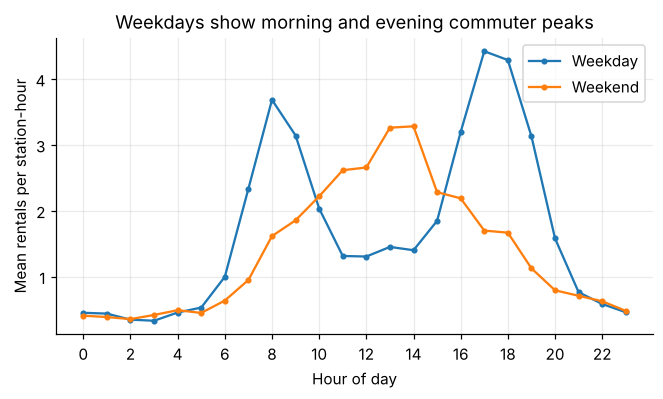

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, m in [("Weekday", ~df.weekend), ("Weekend", df.weekend)]:
    ax.plot(df[m].groupby("hour").rentals.mean(), marker="o", ms=3, label=label)
ax.set(xlabel="Hour of day", ylabel="Mean rentals per station-hour",
       title="Weekdays show morning and evening commuter peaks")
ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.show()

## Easy 2 – Weekday vs weekend

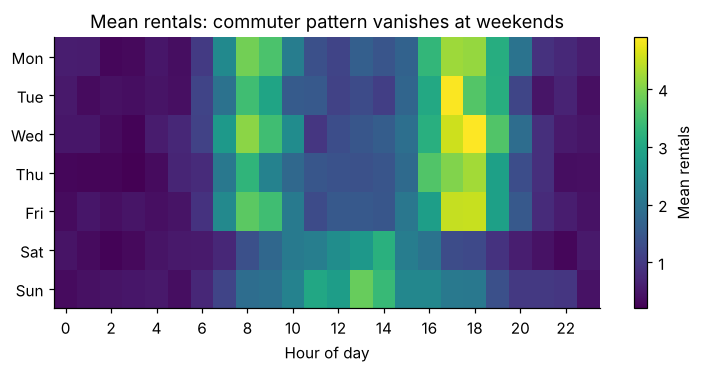

In [4]:
heat = df.groupby(["weekday", "hour"]).rentals.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), day_names); ax.set_xticks(range(0, 24, 2))
ax.set(xlabel="Hour of day", title="Mean rentals: commuter pattern vanishes at weekends")
ax.grid(False); fig.colorbar(im, label="Mean rentals")
plt.show()

## Easy 3 – Warmer means more rentals

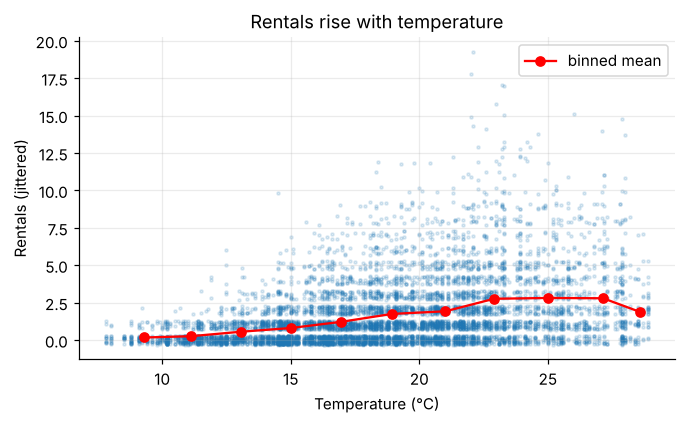

In [5]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(df.temp, df.rentals + rng.uniform(-0.3, 0.3, len(df)), s=4, alpha=0.15)
b = df.groupby(pd.cut(df.temp, np.arange(8, 36, 2)), observed=True).agg(t=("temp", "mean"), r=("rentals", "mean"))
ax.plot(b.t, b.r, "r-o", label="binned mean")
ax.set(xlabel="Temperature (°C)", ylabel="Rentals (jittered)", title="Rentals rise with temperature")
ax.legend(); plt.show()

## Medium 4 – Three hidden station types

Weekday profile for each station, then a map coloured by the hour of peak demand.

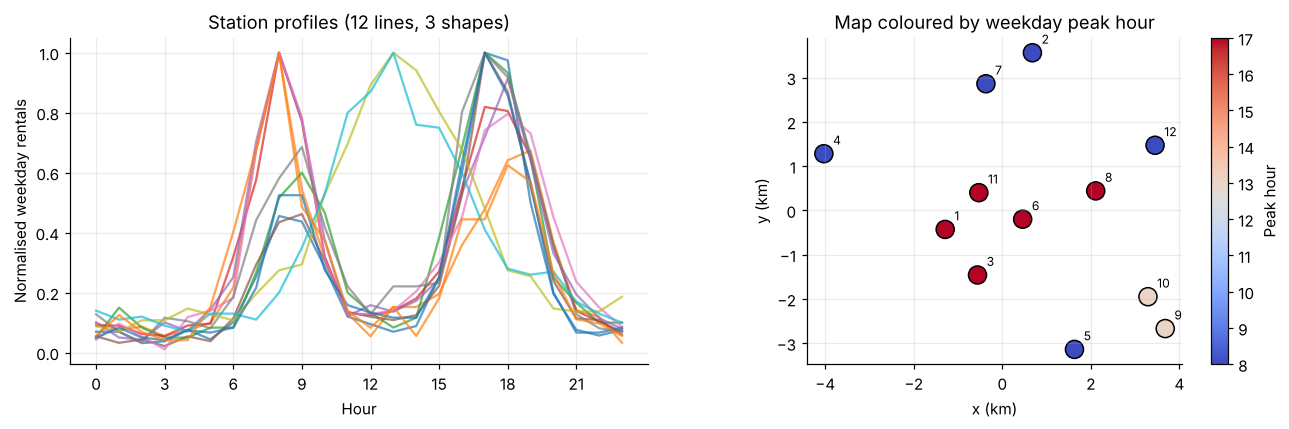

In [6]:
wk = df[~df.weekend]
prof = wk.groupby(["station", "hour"]).rentals.mean().unstack()
prof_n = prof.div(prof.max(axis=1), axis=0)          # normalise so shape, not size, is compared

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, row in prof_n.iterrows():
    axes[0].plot(row.index, row.values, alpha=0.7, label=f"{s}")
axes[0].set(xlabel="Hour", ylabel="Normalised weekday rentals", title="Station profiles (12 lines, 3 shapes)")
axes[0].set_xticks(range(0, 24, 3))

peak = prof.idxmax(axis=1)
loc = df.groupby("station")[["x", "y"]].first()
sc = axes[1].scatter(loc.x, loc.y, c=peak.loc[loc.index], cmap="coolwarm", s=140, edgecolor="k")
for s, r in loc.iterrows():
    axes[1].annotate(str(s), (r.x, r.y), textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set(xlabel="x (km)", ylabel="y (km)", title="Map coloured by weekday peak hour")
axes[1].set_aspect("equal"); fig.colorbar(sc, ax=axes[1], label="Peak hour")
plt.tight_layout(); plt.show()

Clusters: **business** stations in the centre peak in the evening, **residential** stations on a ring peak in the morning, and the two **parks** in the south-east have a flat midday profile (and peak at weekends – see the next cell).

In [7]:
we = df[df.weekend].groupby("station").rentals.mean()
wd = wk.groupby("station").rentals.mean()
ratio = (we / wd).rename("weekend / weekday")
ratio.round(2).to_frame().T

station,1,2,3,4,5,6,7,8,9,10,11,12
weekend / weekday,0.5,0.67,0.56,0.83,0.78,0.46,0.76,0.47,1.63,1.62,0.51,0.91


## Medium 5 – Rain hurts weekends more

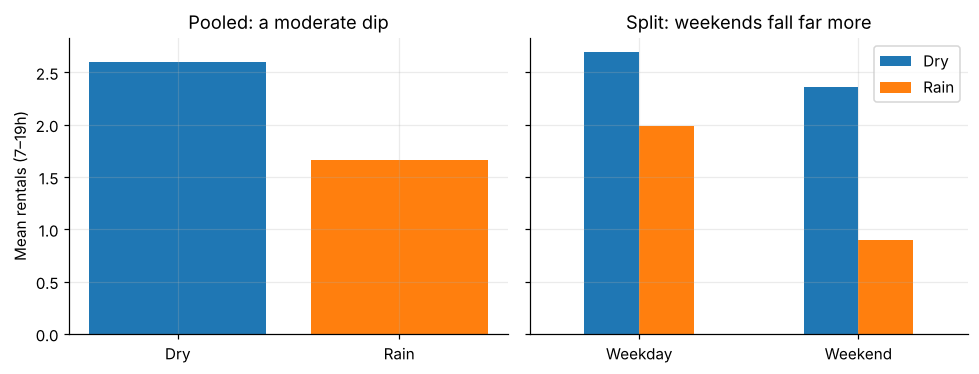

Weekday    0.74
Weekend    0.38
Name: rain/dry ratio, dtype: float64


In [8]:
day = df[df.hour.between(7, 19)]
g = day.groupby(["weekend", "rain"]).rentals.mean().unstack()
g.index = ["Weekday", "Weekend"]
g.columns = ["Dry", "Rain"]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
pooled = day.groupby("rain").rentals.mean()
axes[0].bar(["Dry", "Rain"], pooled.values, color=["tab:blue", "tab:orange"])
axes[0].set(title="Pooled: a moderate dip", ylabel="Mean rentals (7–19h)")
g.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:orange"])
axes[1].set(title="Split: weekends fall far more")
plt.tight_layout(); plt.show()
print((g["Rain"] / g["Dry"]).round(2).rename("rain/dry ratio"))

## Hard 6 – The temperature effect turns over above 24 °C

Only the heatwave (days 19–24) goes this warm and it includes a weekend, so weekdays only, daytime hours, binned means.

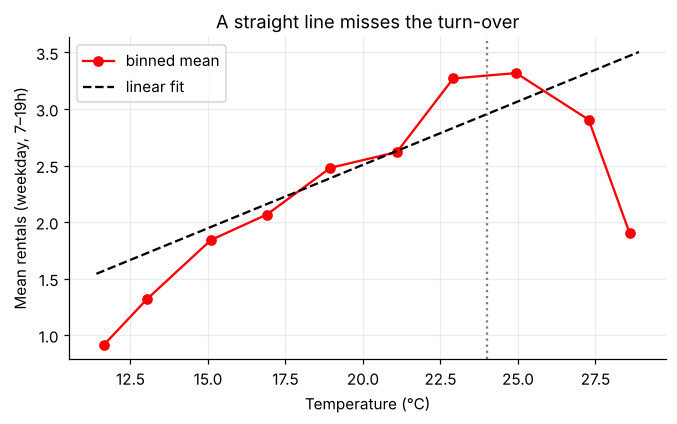

temp,"(10, 12]","(12, 14]","(14, 16]","(16, 18]","(18, 20]","(20, 22]","(22, 24]","(24, 26]","(26, 28]","(28, 30]"
t,11.65,13.04,15.10,16.90,18.95,21.10,22.91,24.94,27.28,28.6
r,0.92,1.32,1.84,2.07,2.48,2.62,3.27,3.32,2.90,1.9
n,24.00,84.00,252.00,420.00,624.00,612.00,468.00,312.00,252.00,72.0


In [9]:
sub = df[(~df.weekend) & df.hour.between(7, 19)]
bins = np.arange(8, 36, 2)
b = sub.groupby(pd.cut(sub.temp, bins), observed=True).agg(t=("temp", "mean"), r=("rentals", "mean"), n=("rentals", "size"))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(b.t, b.r, "r-o", label="binned mean")
slope, icpt = np.polyfit(sub.temp, sub.rentals, 1)
tt = np.linspace(sub.temp.min(), sub.temp.max(), 50)
ax.plot(tt, icpt + slope * tt, "k--", label="linear fit")
ax.axvline(24, color="grey", ls=":")
ax.set(xlabel="Temperature (°C)", ylabel="Mean rentals (weekday, 7–19h)",
       title="A straight line misses the turn-over")
ax.legend(); plt.show()
b.round(2).T

## Hard 7 – Capacity ceiling

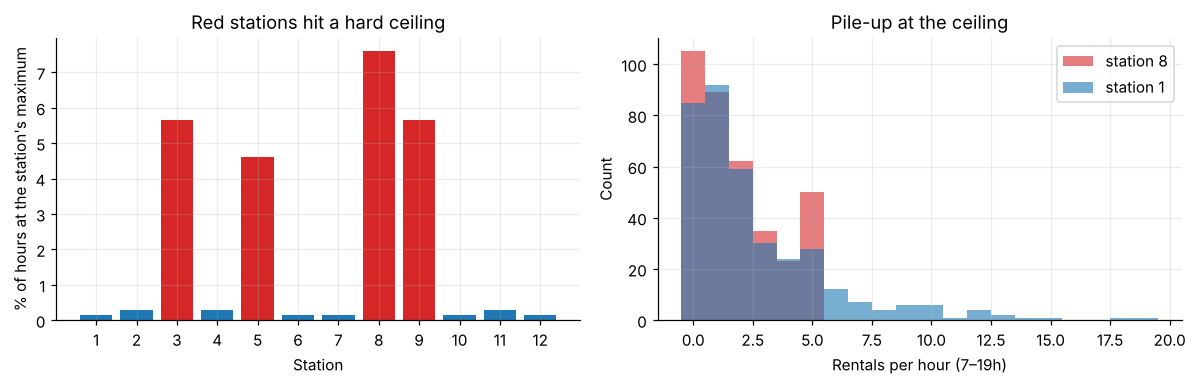

station,1,2,3,4,5,6,7,8,9,10,11,12
max,19.000,10.000,4.000,14.000,9.000,16.000,17.000,5.000,8.000,17.000,11.000,9.000
share_at_max,0.001,0.003,0.057,0.003,0.046,0.001,0.001,0.076,0.057,0.001,0.003,0.001


In [10]:
mx = df.groupby("station").rentals.agg(max="max", share_at_max=lambda s: (s == s.max()).mean())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colors = np.where(mx.share_at_max > 0.02, "tab:red", "tab:blue")
axes[0].bar(mx.index.astype(str), mx.share_at_max * 100, color=colors)
axes[0].set(xlabel="Station", ylabel="% of hours at the station's maximum",
            title="Red stations hit a hard ceiling")

capped = mx.share_at_max.idxmax()
free = mx.share_at_max.idxmin()
for s, c in [(capped, "tab:red"), (free, "tab:blue")]:
    v = df[(df.station == s) & df.hour.between(7, 19)].rentals
    axes[1].hist(v, bins=np.arange(v.max() + 2) - 0.5, alpha=0.6, color=c, label=f"station {s}")
axes[1].set(xlabel="Rentals per hour (7–19h)", ylabel="Count", title="Pile-up at the ceiling")
axes[1].legend(); plt.tight_layout(); plt.show()
mx.round(3).T

## Red herring – Humidity

Humidity looks related to rentals, but it only tracks rain and temperature.

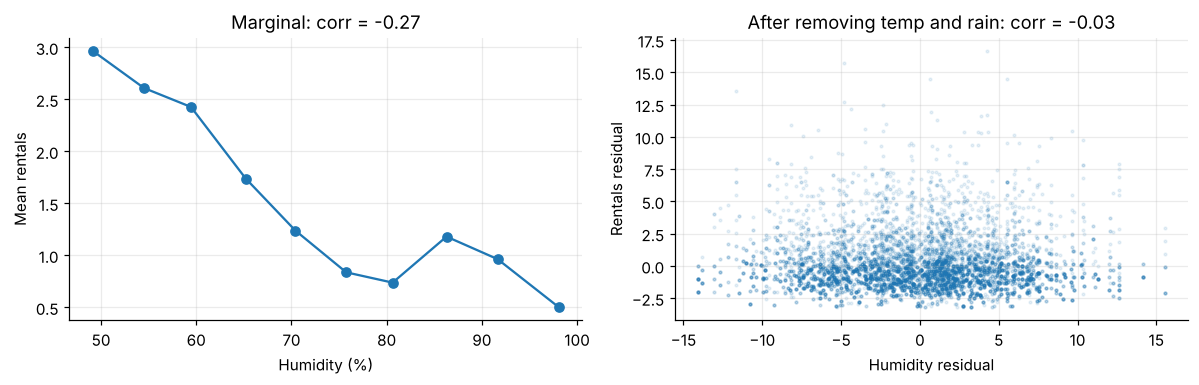

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
b = df.groupby(pd.cut(df.humidity, 10), observed=True).agg(h=("humidity", "mean"), r=("rentals", "mean"))
axes[0].plot(b.h, b.r, "o-")
axes[0].set(xlabel="Humidity (%)", ylabel="Mean rentals", title=f"Marginal: corr = {df.rentals.corr(df.humidity):.2f}")

# partial out temperature and rain
X = np.column_stack([np.ones(len(df)), df.temp, df.temp ** 2, df.rain])
res = lambda y: y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
r_res, h_res = res(df.rentals.values), res(df.humidity.values)
axes[1].scatter(h_res, r_res, s=3, alpha=0.1)
axes[1].set(xlabel="Humidity residual", ylabel="Rentals residual",
            title=f"After removing temp and rain: corr = {np.corrcoef(r_res, h_res)[0, 1]:.2f}")
plt.tight_layout(); plt.show()

In [12]:
# Wind is pure noise
print("corr(rentals, wind) = %.3f" % df.rentals.corr(df.wind))

corr(rentals, wind) = 0.024
